In [8]:
import os

print('Current directory:', os.getcwd())
print('Files in data:', os.listdir('data') if os.path.exists('data') else 'data folder not here')


Current directory: C:\Users\HP\customer-segmentation-rfm
Files in data: ['online_retail.csv']


In [9]:
import pandas as pd

df = pd.read_csv('data/online_retail.csv', encoding='ISO-8859-1')

print('Shape:', df.shape)
print('\nMissing values:\n', df.isnull().sum())
df.head()

Shape: (541909, 8)

Missing values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
# 1. Missing CustomerID drop karo
df_clean = df.dropna(subset=['CustomerID']).copy()

# CustomerID ko clean integer/string format mein rakho
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

# 2. InvoiceDate ko datetime mein convert karo
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# 3. Positive Quantity aur UnitPrice filter karo
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)].copy()

# 4. TotalSpend column banao
df_clean['TotalSpend'] = df_clean['Quantity'] * df_clean['UnitPrice']

print('Cleaned shape:', df_clean.shape)
print('Date range:', df_clean['InvoiceDate'].min(), 'to', df_clean['InvoiceDate'].max())
df_clean.head()

Cleaned shape: (397884, 9)
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalSpend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [11]:
import datetime as dt

# Dataset ki aakhiri date ke 1 din baad ka snapshot date lete hain
snapshot_date = df_clean['InvoiceDate'].max() + dt.timedelta(days=1)

rfm = (
    df_clean.groupby('CustomerID')
    .agg({
        'InvoiceDate': lambda x: (snapshot_date - x.max()).days,
        'InvoiceNo': 'nunique',
        'TotalSpend': 'sum',
    })
    .reset_index()
)

rfm.columns = ['CustomerID', 'Recency', 'Frequency', 'Monetary']

print('Total customers:', len(rfm))
print(rfm.describe().round(2))
rfm.head()

Total customers: 4338
       CustomerID  Recency  Frequency   Monetary
count     4338.00  4338.00    4338.00    4338.00
mean     15300.41    92.54       4.27    2054.27
std       1721.81   100.01       7.70    8989.23
min      12346.00     1.00       1.00       3.75
25%      13813.25    18.00       1.00     307.41
50%      15299.50    51.00       2.00     674.48
75%      16778.75   142.00       5.00    1661.74
max      18287.00   374.00     209.00  280206.02


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1. Skewness kam karne ke liye log1p transformation
rfm_log = np.log1p(rfm[['Recency', 'Frequency', 'Monetary']])

# 2. Features ko standard scale par laana
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Check karne ke liye scaled data ka summary
rfm_scaled_df = pd.DataFrame(
    rfm_scaled, columns=['Recency_scaled', 'Frequency_scaled', 'Monetary_scaled']
)
print(rfm_scaled_df.describe().round(2))

       Recency_scaled  Frequency_scaled  Monetary_scaled
count         4338.00           4338.00          4338.00
mean            -0.00             -0.00             0.00
std              1.00              1.00             1.00
min             -2.34             -0.96            -4.00
25%             -0.66             -0.96            -0.69
50%              0.09             -0.36            -0.06
75%              0.84              0.65             0.65
max              1.56              5.86             4.73


C:\Users\HP\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\HP\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\HP\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\HP\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

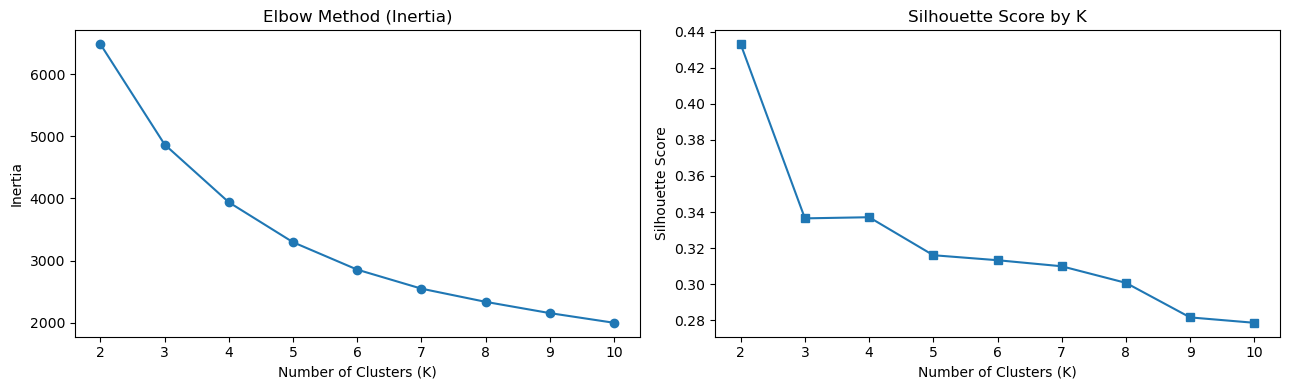

K=2 -> Silhouette Score: 0.4329
K=3 -> Silhouette Score: 0.3365
K=4 -> Silhouette Score: 0.3371
K=5 -> Silhouette Score: 0.3161
K=6 -> Silhouette Score: 0.3133
K=7 -> Silhouette Score: 0.3100
K=8 -> Silhouette Score: 0.3008
K=9 -> Silhouette Score: 0.2817
K=10 -> Silhouette Score: 0.2787


In [13]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

wcss = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(rfm_scaled)
    wcss.append(model.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_values, wcss, marker='o')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_values, silhouette_scores, marker='s')
axes[1].set_title('Silhouette Score by K')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

for k, sil in zip(k_values, silhouette_scores):
    print(f'K={k} -> Silhouette Score: {sil:.4f}')

In [14]:
# 1. Final K-Means model with K=4
kmeans_final = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans_final.fit_predict(rfm_scaled)

# 2. Each Cluster ke average RFM values calculate karo
cluster_profile = (
    rfm.groupby('Cluster')
    .agg(
        {
            'Recency': 'mean',
            'Frequency': 'mean',
            'Monetary': 'mean',
            'CustomerID': 'count',
        }
    )
    .rename(columns={'CustomerID': 'CustomerCount'})
    .round(2)
)

print(cluster_profile)

         Recency  Frequency  Monetary  CustomerCount
Cluster                                             
0          18.12       2.15    551.82            837
1          12.13      13.71   8074.27            716
2          71.08       4.08   1802.83           1173
3         182.50       1.32    343.45           1612


In [15]:
# Values dekh kar clusters assign karo (Apne table ke summary numbers se match kar lena):
# Cluster 0, 1, 2, 3 ke order dataset ke hisab se mapping kar sakte ho:

segment_map = {
    0: 'At-Risk / Dormant',
    1: 'Loyal High Spenders',
    2: 'New / Low Spend Recent',
    3: 'Champions (Best Customers)',
}

# Apply map (Modify keys if your cluster index is different)
rfm['Segment'] = rfm['Cluster'].map(segment_map)
rfm.head()

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,12346,326,1,77183.60,2,New / Low Spend Recent
1,12347,2,7,4310.00,1,Loyal High Spenders
2,12348,75,4,1797.24,2,New / Low Spend Recent
3,12349,19,1,1757.55,0,At-Risk / Dormant
4,12350,310,1,334.40,3,Champions (Best Customers)


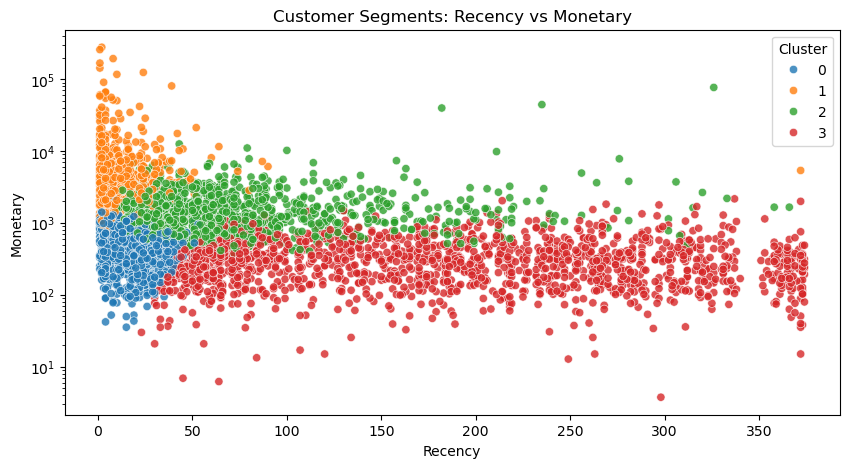

In [16]:
import seaborn as sns

plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=rfm,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='tab10',
    alpha=0.8,
)
plt.yscale('log')  # Log scale for better visibility of spread
plt.title('Customer Segments: Recency vs Monetary')
plt.show()